# Piloto ou carro? O teste mais justo é contra o companheiro

**Pergunta de negócio:** quando dois pilotos dividem o mesmo carro na mesma temporada, com que frequência um supera o outro e quanto dessa vantagem aparece em equipes dominantes?

A comparação com colegas reduz diferenças de equipamento. Usamos posição final (comparável entre eras) e damos o mesmo peso a cada corrida.

## Dados e preparo

- **Fonte:** CSVs históricos locais, espelhando o conjunto [Formula 1 World Championship (1950–2024), de Rohan Rao no Kaggle](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020), baseado no Ergast Motor Racing Data.
- **Licença:** os arquivos locais não identificam a licença deste snapshot. Confira os termos exibidos na fonte Kaggle e nos dados Ergast antes de redistribuir.
- **Período:** 1950–2024. A base registra as 500 Milhas de Indianápolis como rodada do campeonato em 1950–1960; excluímos esse evento, que não era um GP de F1.
- **Limpeza:** usamos `positionOrder > 0`, excluindo sem classificação (inclui DNS/DNQ), e removemos duplicatas por corrida/piloto/equipe e registros sem chaves necessárias. Não comparamos pontos absolutos entre eras.
- **Escopo:** resultados de GPs; resultados de Sprint não entram nesta comparação.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
races = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId", "year", "name"]).rename(columns={"name": "event"})
results = pd.read_csv(DATA_DIR / "results.csv", usecols=["raceId", "driverId", "constructorId", "positionOrder", "points"])
drivers = pd.read_csv(DATA_DIR / "drivers.csv", usecols=["driverId", "forename", "surname"])
constructors = pd.read_csv(DATA_DIR / "constructors.csv", usecols=["constructorId", "name"])
base = (results.merge(races, on="raceId", validate="many_to_one")
        .merge(drivers, on="driverId", validate="many_to_one")
        .merge(constructors, on="constructorId", validate="many_to_one"))
base = base.loc[base.positionOrder.gt(0) & base.driverId.notna() & base.constructorId.notna() & base.event.ne("Indianapolis 500")].copy()
base = base.drop_duplicates(["raceId", "driverId", "constructorId"])
base["piloto"] = base.forename.str.strip() + " " + base.surname.str.strip()
print(f"Temporadas: {base.year.min()}–{base.year.max()} | corridas: {base.raceId.nunique():,} | resultados classificados: {len(base):,}")

Temporadas: 1950–2024 | corridas: 1,114 | resultados classificados: 26,292


## Método: colega na mesma equipe e corrida

Para cada piloto e GP, calculamos a fração de colegas classificados que ele terminou à frente. Em equipes com mais de dois pilotos, primeiro tiramos a média dos colegas naquela corrida; depois cada GP tem peso igual. O ranking histórico exige ao menos 30 GPs com pelo menos um colega comparável.

O eixo de contexto da equipe usa a participação da equipe nos pontos totais daquela temporada. Essa medida incorpora o desempenho dos próprios pilotos; é descritiva, não independente, não entra no ranking e não permite inferir causalidade.

In [2]:
a = base[["raceId", "year", "constructorId", "driverId", "piloto", "positionOrder"]]
pairs = a.merge(a, on=["raceId", "year", "constructorId"], suffixes=("_piloto", "_colega"))
pairs = pairs.loc[pairs.driverId_piloto.ne(pairs.driverId_colega)].copy()
pairs["venceu_colega"] = pairs.positionOrder_piloto.lt(pairs.positionOrder_colega)
# Reduz os colegas de cada piloto a uma taxa por GP: cada corrida conta uma vez.
per_gp = (pairs.groupby(["raceId", "year", "constructorId", "driverId_piloto", "piloto_piloto"], as_index=False)
          .agg(taxa_gp=("venceu_colega", "mean")))
peer_season = (per_gp.groupby(["year", "constructorId", "driverId_piloto", "piloto_piloto"], as_index=False)
               .agg(corridas_comparaveis=("raceId", "nunique"), taxa_media_gp=("taxa_gp", "mean")))
team_points = (base.groupby(["year", "constructorId", "name"], as_index=False).points.sum()
               .rename(columns={"points": "pontos_equipe"}))
season_points = team_points.groupby("year").pontos_equipe.transform("sum")
team_points["participacao_pontos"] = team_points.pontos_equipe.div(season_points.where(season_points.ne(0)))
peer_season = peer_season.merge(team_points[["year", "constructorId", "name", "participacao_pontos"]],
                                on=["year", "constructorId"], validate="many_to_one").dropna(subset=["participacao_pontos"])


### Dispersão: participação da equipe e desempenho contra colegas

Cada ponto representa um piloto em uma equipe numa temporada. O eixo vertical é a média da taxa de colegas superados por GP, com peso igual por corrida; 50% marca equilíbrio. O eixo horizontal contextualiza a participação da equipe nos pontos do mesmo ano.

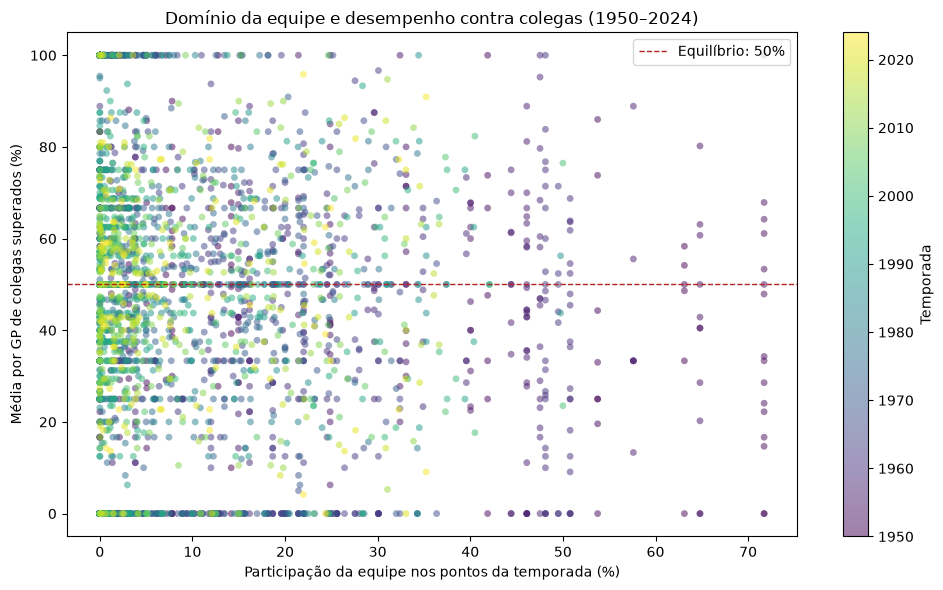

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(peer_season.participacao_pontos * 100, peer_season.taxa_media_gp * 100,
                c=peer_season.year, cmap="viridis", alpha=.5, s=24, linewidths=0)
ax.axhline(50, color="firebrick", linestyle="--", linewidth=1, label="Equilíbrio: 50%")
ax.set(title="Domínio da equipe e desempenho contra colegas (1950–2024)",
       xlabel="Participação da equipe nos pontos da temporada (%)",
       ylabel="Média por GP de colegas superados (%)")
fig.colorbar(sc, ax=ax, label="Temporada")
ax.legend(); fig.tight_layout(); plt.show()

**Leitura do gráfico.** O gráfico mostra associação entre contexto da equipe e confronto direto, não causa. A taxa do eixo vertical conta cada GP igualmente, inclusive quando há mais de dois colegas classificados.

## Ranking histórico por GP comparável

A taxa de cada piloto é a média simples das taxas por GP ao longo da carreira. Exigimos 30 corridas em que havia ao menos um colega classificado na mesma equipe. Mostramos o número de GPs para contextualizar a amostra.

In [4]:
leaderboard = (per_gp.groupby(["driverId_piloto", "piloto_piloto"], as_index=False)
               .agg(corridas_comparaveis=("raceId", "nunique"), taxa_vitorias=("taxa_gp", "mean")))
leaderboard = (leaderboard.loc[leaderboard.corridas_comparaveis.ge(30)]
               .sort_values(["taxa_vitorias", "corridas_comparaveis"], ascending=[False, False])
               .head(10).reset_index(drop=True))
leaderboard["taxa_pct"] = leaderboard.taxa_vitorias * 100
leaderboard[["piloto_piloto", "corridas_comparaveis", "taxa_pct"]].round({"taxa_pct": 1})

,piloto_piloto,corridas_comparaveis,taxa_pct
0,Juan Fangio,51,79.7
1,Max Verstappen,209,73.7
2,Jim Clark,66,73.1
3,Alberto Ascari,31,70.8
4,Pedro Rodríguez,49,70.7
5,Mika Salo,111,70.3
6,Nicola Larini,57,70.2
7,Jonathan Palmer,76,69.7
8,Roberto Moreno,71,69.0
9,Mick Schumacher,44,68.2


### Top 10 de aproveitamento contra colegas

As barras ordenam os pilotos elegíveis pela média, com peso igual, da fração de colegas superados em cada GP comparável. O limiar de 30 corridas reduz a influência de carreiras curtas, sem eliminar diferenças de contexto.

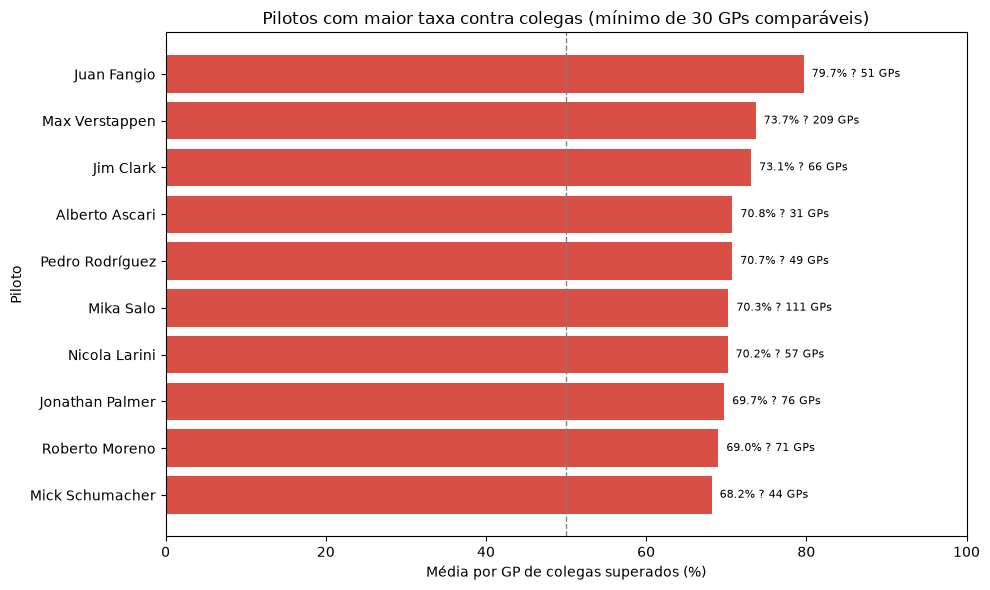

In [5]:
plot_rank = leaderboard.sort_values("taxa_pct")
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_rank.piloto_piloto, plot_rank.taxa_pct, color="#d94f45")
ax.axvline(50, color="gray", linestyle="--", linewidth=1)
ax.set(title="Pilotos com maior taxa contra colegas (mínimo de 30 GPs comparáveis)",
       xlabel="Média por GP de colegas superados (%)", ylabel="Piloto", xlim=(0, 100))
for bar, (_, row) in zip(bars, plot_rank.iterrows()):
    ax.text(min(bar.get_width() + 1, 91), bar.get_y() + bar.get_height()/2,
            f"{row.taxa_pct:.1f}% ? {row.corridas_comparaveis} GPs", va="center", fontsize=8)
fig.tight_layout(); plt.show()

**Leitura do ranking.** O resultado responde quem terminou à frente dos colegas com maior frequência por corrida comparável. Não identifica sozinho o melhor piloto de todos os tempos: colegas, calendários, confiabilidade e regulamentos diferem entre carreiras.

## Principais achados

Os indicadores são calculados nas células desta análise e refletem os CSVs incluídos no repositório.

In [6]:
n_comp = len(pairs)
share_above = peer_season.taxa_media_gp.gt(.5).mean() * 100
median_team = peer_season.groupby(["year", "constructorId"]).participacao_pontos.first().median() * 100
lead = leaderboard.iloc[0]
print(f"- A base cobre {base.year.min()}–{base.year.max()}, com {base.raceId.nunique():,} GPs e {len(base):,} resultados classificados.")
print(f"- Foram formados {n_comp:,} comparações dirigidas piloto-colega nos GPs; cada corrida pesa igualmente nas taxas.")
print(f"- {share_above:.1f}% dos recortes piloto-temporada-equipe ficaram acima de 50% na média por GP.")
print(f"- A participação mediana de uma equipe nos pontos da temporada foi {median_team:.1f}%.")
print(f"- Com mínimo de 30 GPs comparáveis, {lead.piloto_piloto} lidera com {lead.taxa_pct:.1f}% em {lead.corridas_comparaveis} GPs.")

- A base cobre 1950–2024, com 1,114 GPs e 26,292 resultados classificados.
- Foram formados 34,846 comparações dirigidas piloto-colega nos GPs; cada corrida pesa igualmente nas taxas.
- 40.0% dos recortes piloto-temporada-equipe ficaram acima de 50% na média por GP.
- A participação mediana de uma equipe nos pontos da temporada foi 3.6%.
- Com mínimo de 30 GPs comparáveis, Juan Fangio lidera com 79.7% em 51 GPs.


## Limitações e próximos passos

- `positionOrder > 0` inclui chegadas classificadas pela regra de distância mesmo após abandono; DNS, DNQ e entradas sem posição classificada ficam de fora. O snapshot também não foi usado para resultados Sprint.
- A base não separa ritmo, confiabilidade, estratégia ou condições da corrida. Substitutos podem aparecer em poucas etapas e os colegas nem sempre disputaram a temporada inteira juntos.
- A participação da equipe nos pontos incorpora o desempenho dos pilotos. Ela serve apenas como contexto descritivo, não entra no ranking e não permite inferir causalidade.
- Posição final melhora a comparação entre sistemas de pontuação, mas grids, regulamentos, formatos e confiabilidade mudaram ao longo do tempo.
- A licença exata deste snapshot não está identificada nos CSVs; confirme os termos na fonte antes de redistribuir. Uma extensão pode parear apenas janelas de inscrição simultânea e separar pilotos titulares de substitutos.